# EAGLE · 03 — Localizar subestaciones AT por celda

Este notebook **lee** la malla territorial generada en EAGLE 01 y extrae emplazamientos de subestaciones a partir de los buses de `base.nc` de PyPSA-Eur. Agrupa buses con coordenadas iguales (dentro de la precisión definida), cruza sus ubicaciones con las celdas y exporta resultados **sin modificar los archivos de origen**.

**Advertencia:** los emplazamientos inferidos de `base.nc` son *emplazamientos del modelo*, no un inventario verificado de instalaciones físicas. El conteo puede diferir del real por representación, precisión y cobertura del modelo. Una celda con cero significa «ninguna encontrada en esta fuente», no «ninguna existente».

## 1 · Configuración

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import pypsa

RUTA_CELDAS = Path('data/base/eagle_territorio.gpkg')
RUTA_RED = Path(r'C:\workspace\EAGLE\external\pypsa-eur\resources\eagle-iberia\networks\base.nc')
OUT_DIR = Path('data/enriquecido')
OUT_DIR.mkdir(parents=True, exist_ok=True)

TENSION_MIN_KV = 110
# Para agrupar buses de una misma ubicación en la red: redondeo en metros
PRECISION_AGRUPACION_M = 10

assert RUTA_CELDAS.exists(), f'Falta GeoPackage: {RUTA_CELDAS.resolve()}'
assert RUTA_RED.exists(), f'No se encuentra base.nc: {RUTA_RED.resolve()}. Ajusta RUTA_RED.'

celdas = gpd.read_file(RUTA_CELDAS, layer='celdas')
assert celdas.crs is not None and celdas.celda_id.is_unique
red = pypsa.Network(str(RUTA_RED))
print('Celdas:',len(celdas),'Buses en red:',len(red.buses))
print('Columnas disponibles en buses:', list(red.buses.columns))

c:\Users\naiar\anaconda3\envs\pypsa-eur\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()
c:\Users\naiar\anaconda3\envs\pypsa-eur\Lib\site-packages\xarray\backends\plugins.py:109: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
c:\Users\naiar\anaconda3\envs\pypsa-eur\Lib\site-packages\rasterio\env.py:679: RuntimeWarning: Cannot find gdalvrt.xsd (GDAL_DATA is not defined)
  elif GDALDataFinder().find_file("gdalvrt.xsd"):
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.4)
INFO:pypsa.network.io:Imported network 'PyPSA-Eur (osm vlatest)' has buses, carriers, lines, links, shapes, transformers


Celdas: 6356 Buses en red: 2436
Columnas disponibles en buses: ['v_nom', 'type', 'x', 'y', 'carrier', 'unit', 'location', 'v_mag_pu_set', 'v_mag_pu_min', 'v_mag_pu_max', 'control', 'generator', 'sub_network', 'symbol', 'under_construction', 'tags', 'country', 'geometry', 'onshore_bus', 'substation_lv', 'substation_off']


## 2 Extraer buses AT y detectar emplazamientos

Se conservan buses con coordenadas válidas y tensión nominal >= umbral. Cuando `substation_lv` o `substation_off` están presentes, se utilizan como señal de subestación del modelo; cuando faltan, el resultado se identifica únicamente como **candidatos basados en buses AT**. Dos buses con las mismas coordenadas redondeadas se tratan como un emplazamiento. No es una deduplicación perfecta de instalaciones físicas.

In [3]:
b = red.buses.copy()
obligatorias = {'x','y','v_nom'}
assert obligatorias.issubset(b.columns), f'Faltan columnas: {obligatorias-set(b.columns)}'
b['v_nom'] = pd.to_numeric(b['v_nom'], errors='coerce')
b['x'] = pd.to_numeric(b['x'], errors='coerce')
b['y'] = pd.to_numeric(b['y'], errors='coerce')
b['bus_id'] = b.index.astype(str)

filtro = b[['x','y','v_nom']].notna().all(axis=1) & (b['v_nom'] >= TENSION_MIN_KV)
filtro &= b['x'].between(-180,180) & b['y'].between(-90,90)
campos_sub = [c for c in ['substation_lv','substation_off'] if c in b.columns]
if campos_sub:
    filtro &= b[campos_sub].fillna(False).astype(bool).any(axis=1)
    origen = 'Buses AT marcados como subestación en PyPSA-Eur'
else:
    origen = 'Candidatos: buses AT sin indicador explícito de subestación'
    print('AVISO: base.nc no contiene indicadores de subestación; los resultados serán candidatos basados en buses.')

b = b.loc[filtro].copy()
assert len(b), 'No hay buses que cumplan los filtros. Revisa columnas y umbral.'
puntos = gpd.GeoDataFrame(b, geometry=gpd.points_from_xy(b.x,b.y), crs='EPSG:4326').to_crs(celdas.crs)
# Agrupar en CRS métrico por posición de modelo (no por cercanía arbitraria)
puntos['grupo_x'] = (puntos.geometry.x / PRECISION_AGRUPACION_M).round().astype('int64')
puntos['grupo_y'] = (puntos.geometry.y / PRECISION_AGRUPACION_M).round().astype('int64')
puntos['tension_kv'] = puntos['v_nom']

sitios_tabla = (puntos.groupby(['grupo_x','grupo_y'], as_index=False)
   .agg(num_buses=('bus_id','size'), tension_max_kv=('tension_kv','max'),
        tensiones_kv=('tension_kv', lambda s: ', '.join(map(str,sorted(set(s))))),
        buses_pypsa=('bus_id',lambda s: ', '.join(s))))
sitios_tabla['subestacion_id'] = ['AT_'+str(i).zfill(6) for i in range(1,len(sitios_tabla)+1)]
sitios = gpd.GeoDataFrame(sitios_tabla,
    geometry=gpd.points_from_xy(sitios_tabla.grupo_x*PRECISION_AGRUPACION_M,
                                sitios_tabla.grupo_y*PRECISION_AGRUPACION_M), crs=celdas.crs)
print('Origen:',origen)
print('Buses seleccionados:',len(puntos),'| Emplazamientos inferidos:',len(sitios))
display(sitios.drop(columns='geometry').head(10))

Origen: Buses AT marcados como subestación en PyPSA-Eur
Buses seleccionados: 2435 | Emplazamientos inferidos: 2435


,grupo_x,grupo_y,num_buses,tension_max_kv,tensiones_kv,buses_pypsa,subestacion_id
0,265005,195360,1,220.0,220.0,way/144651478-220,AT_000001
1,265851,195494,1,220.0,220.0,way/151168335-220,AT_000002
2,265853,195496,1,400.0,400.0,way/151168335-400,AT_000003
3,265930,194817,1,220.0,220.0,way/1202443036-220,AT_000004
4,266105,195512,1,220.0,220.0,virtual_way/144654743:0-220,AT_000005
5,266140,195343,1,220.0,220.0,way/144654759-220,AT_000006
6,266332,194924,1,220.0,220.0,way/1202440398-220,AT_000007
7,266361,193123,1,400.0,400.0,way/171253574-400,AT_000008
8,266457,195601,1,220.0,220.0,virtual_way/24635847:0-220,AT_000009
9,266466,195361,1,220.0,220.0,way/24636062-220,AT_000010


## 3 · Asignación espacial a la malla

Se utiliza `within` para evitar asignaciones dobles. Las ubicaciones exactamente sobre el borde de dos celdas se asignan de forma determinista con `intersects` a una sola de ellas. Las ubicaciones fuera de la malla quedan identificadas y no se cuentan.

In [4]:
enlace = gpd.sjoin(sitios[['subestacion_id','tension_max_kv','geometry']],
                    celdas[['celda_id','geometry']], how='left', predicate='within')
sin_asignar = enlace[enlace.celda_id.isna()].copy()
if len(sin_asignar):
    alternativas = gpd.sjoin(sin_asignar.drop(columns=['index_right','celda_id']),
                             celdas[['celda_id','geometry']], how='left', predicate='intersects')
    alternativas = alternativas.dropna(subset=['celda_id']).sort_values(['subestacion_id','celda_id'])
    alternativas = alternativas.drop_duplicates('subestacion_id')
    enlace = pd.concat([enlace[enlace.celda_id.notna()], alternativas], ignore_index=True)
else:
    enlace = enlace[enlace.celda_id.notna()].copy()
assert not enlace.subestacion_id.duplicated().any()

conteos = (enlace.groupby('celda_id').agg(
    num_subestaciones_at=('subestacion_id','nunique'),
    tension_max_subestacion_kv=('tension_max_kv','max')).reset_index())
resultado = celdas.merge(conteos, on='celda_id', how='left', validate='one_to_one')
resultado['num_subestaciones_at'] = resultado['num_subestaciones_at'].fillna(0).astype(int)
resultado['tiene_subestacion_at'] = resultado['num_subestaciones_at'] > 0

sitios_asignados = sitios.merge(enlace[['subestacion_id','celda_id']],on='subestacion_id',how='left',validate='one_to_one')
print('Total celdas:',len(resultado))
print('Celdas con subestaciones AT del modelo:',resultado.tiene_subestacion_at.sum())
print('Emplazamientos asignados:',resultado.num_subestaciones_at.sum())
print('Emplazamientos sin celda:',sitios_asignados.celda_id.isna().sum())
display(resultado.drop(columns='geometry').sort_values('num_subestaciones_at',ascending=False).head(15))

Total celdas: 6356
Celdas con subestaciones AT del modelo: 711
Emplazamientos asignados: 1232
Emplazamientos sin celda: 1203


,celda_id,pais,territorio,latitud,longitud,superficie_tierra_km2,porcentaje_tierra,num_subestaciones_at,tension_max_subestacion_kv,tiene_subestacion_at
3235,E.109.164,España,España peninsular,40.398947,-3.513553,100.000000,100.000000,8,400.0,True
5962,E.140.173,España,España peninsular,43.285212,-3.049973,97.406265,97.406265,8,400.0,True
3143,E.108.162,España,España peninsular,40.277715,-3.725871,100.000000,100.000000,8,220.0,True
5808,E.138.143,España,España peninsular,42.585157,-6.619242,100.000000,100.000000,8,400.0,True
692,E.079.138,España,España peninsular,37.283818,-5.855303,100.000000,100.000000,7,400.0,True
4688,E.124.131,Portugal,Portugal continental,41.111877,-7.679106,100.000000,100.000000,7,400.0,True
3652,E.113.212,España,España peninsular,41.370748,2.055480,100.000000,100.000000,7,400.0,True
3234,E.109.163,España,España peninsular,40.382816,-3.629427,100.000000,100.000000,7,220.0,True
1955,E.094.188,España,España peninsular,39.401945,-0.494922,100.000000,100.000000,6,400.0,True
2947,E.106.145,España,España peninsular,39.804141,-5.640383,100.000000,100.000000,6,400.0,True


## 4 · Visualización

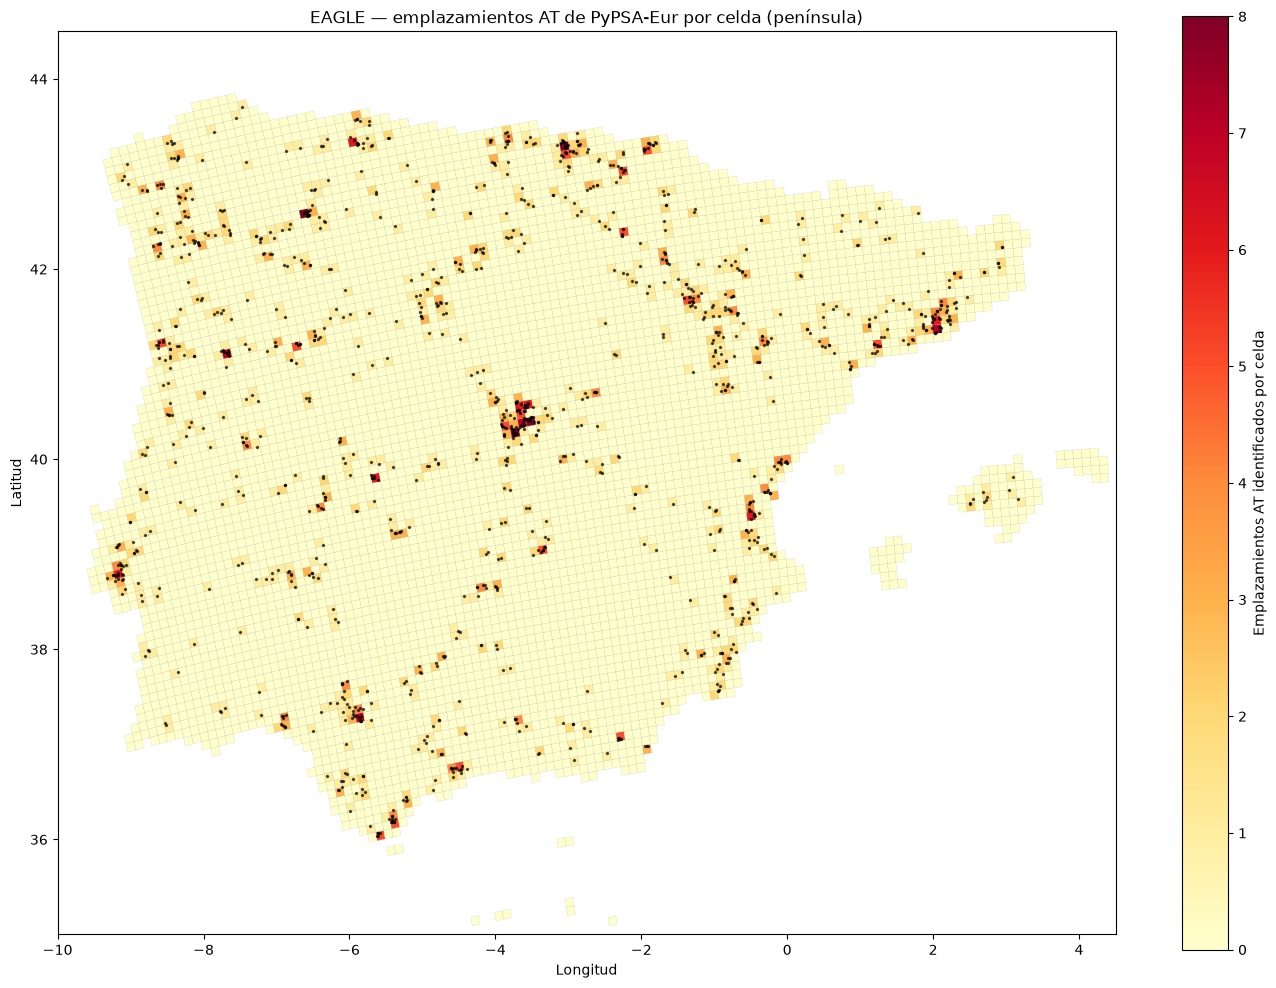

In [5]:
# Gráfico en la península; cambia límites para otras regiones
fig, ax = plt.subplots(figsize=(14,10))
resultado.to_crs(4326).plot(ax=ax, column='num_subestaciones_at', cmap='YlOrRd',
                   linewidth=.1, edgecolor='#999999', legend=True,
                   legend_kwds={'label':'Emplazamientos AT identificados por celda'})
sitios_asignados.dropna(subset=['celda_id']).to_crs(4326).plot(
    ax=ax, color='black', markersize=2, alpha=.6)
ax.set_xlim(-10,4.5); ax.set_ylim(35,44.5)
ax.set_title('EAGLE — emplazamientos AT de PyPSA-Eur por celda (península)')
ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
plt.tight_layout(); plt.show()

## 5 · Exportar a archivos independientes

In [7]:
ruta_gpkg = OUT_DIR/'eagle_subestaciones_at.gpkg'
ruta_csv = OUT_DIR/'eagle_celdas_subestaciones_at.csv'
ruta_sitios_csv = OUT_DIR/'eagle_emplazamientos_at_pypsa.csv'
if ruta_gpkg.exists(): ruta_gpkg.unlink()
resultado.to_file(ruta_gpkg, layer='celdas_con_subestaciones', driver='GPKG')
sitios_asignados.to_file(ruta_gpkg, layer='emplazamientos_at_pypsa',driver='GPKG',mode='a')
resultado.drop(columns='geometry').to_csv(ruta_csv,index=False)
sitios_asignados.to_crs(4326).assign(longitud=lambda d:d.geometry.x, latitud=lambda d:d.geometry.y).drop(columns='geometry').to_csv(ruta_sitios_csv,index=False)
print('Archivos generados:',ruta_gpkg,ruta_csv,ruta_sitios_csv,sep='- ')

c:\Users\naiar\anaconda3\envs\pypsa-eur\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Cannot find tms_NZTM2000.json (GDAL_DATA is not defined)
  ogr_write(
INFO:pyogrio._io:Created 6,356 records
INFO:pyogrio._io:Created 2,435 records


Archivos generados:- data\enriquecido\eagle_subestaciones_at.gpkg- data\enriquecido\eagle_celdas_subestaciones_at.csv- data\enriquecido\eagle_emplazamientos_at_pypsa.csv


## Nota metodológica

- La presencia es **presencia en la fuente PyPSA-Eur**, no verificación del emplazamiento físico. Los buses son nodos eléctricos y podrían representar instalaciones agregadas.
- Diferentes buses de la misma instalación podrían no compartir coordenadas; y varios elementos de una ubicación podrían agregarse en un único emplazamiento del modelo.
- La precisión puede mejorar utilizando polígonos de subestaciones OSM (`resources/osm/clean/substations_polygon.geojson` o similares) y validando con cartografía oficial.
- Las subestaciones no implican capacidad de conexión disponible: se estudiará en otra fase con flujos, contingencias y límites eléctricos.
- Las celdas incluyen mar en bordes costeros: se recomienda comprobar si los puntos pertenecen al territorio terrestre cuando se incorpore cartografía física validada.